# 04 · Les noms : est-ce que le son d'un nom dit quelque chose du Pokémon ?

L'idée vient de la **symbolique sonore** : en linguistique, on a remarqué que certains sons « vont avec » certaines idées. Par exemple, beaucoup de gens associent les sons durs ou graves (b, d, g) à des choses grosses et lourdes, et les sons doux à des choses petites ou mignonnes. C'est l'idée derrière l'expérience classique « bouba / kiki ».

Des chercheurs ont testé ça sur les Pokémon, c'est ce qu'ils appellent les **Pokémonastics** :
- **Kawahara, Noto & Kumagai (2018)** : en japonais, plus un nom de Pokémon contient de **consonnes voisées** (les kana avec le petit signe ゛, comme ガ, ド, バ), plus le Pokémon est **grand et lourd**. Et plus le nom est **long** (en nombre de mores), plus le Pokémon est **évolué** et **fort** ;
- **Shih et al. (2019)** : ils ont testé la même chose dans 6 langues, dont l'anglais, mais **pas le français**.

Dans ce notebook :
1. on transforme les noms **japonais, français et anglais** en **variables sonores** (longueur, consonnes voisées, sons durs, sons doux). Pour le français et l'anglais, on passe par une **transcription phonétique** (espeak-ng), parce que l'orthographe n'est pas la prononciation ;
2. on essaie de **retrouver le résultat de Kawahara** en japonais, puis dans les deux autres langues ;
3. on fait le test le plus fidèle à son idée : **dans une même lignée, le nom grandit-il quand le Pokémon évolue ?** ;
4. on regarde si le son du nom a un lien avec la **popularité**, en se demandant quel nom chaque public voit vraiment.

La méthode principale, c'est celle du TP1 : la **corrélation de Spearman** (elle travaille sur les rangs, donc elle ne suppose pas de relation linéaire et elle n'est pas gênée par les valeurs extrêmes comme le poids). On y ajoute un test du signe pour les lignées, et un test de Mann-Whitney pour Pokémon of the Year.

In [1]:
import re
import subprocess
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import spearmanr, binomtest, mannwhitneyu
from statsmodels.stats.multitest import multipletests

pd.set_option("display.max_columns", 50)
PROC = Path("../data/processed")
table = pd.read_csv(PROC / "table_maitre.csv", index_col="dex")
print(table.shape)
pop_sources = pd.read_csv(PROC / "popularite_sources.csv", index_col="dex")

(1025, 35)


## 1. Découverte des noms

In [2]:
table[["nom_en", "nom_fr", "nom_ja", "nom_ja_roma"]].sample(10, random_state=1)

,nom_en,nom_fr,nom_ja,nom_ja_roma
dex,,,,
50,Diglett,Taupiqueur,ディグダ,Digda
526,Gigalith,Gigalithe,ギガイアス,Gigaiath
120,Staryu,Stari,ヒトデマン,Hitodeman
630,Mandibuzz,Vaututrice,バルジーナ,Vulgina
187,Hoppip,Granivol,ハネッコ,Hanecco
692,Clauncher,Flingouste,ウデッポウ,Udeppou
474,Porygon-Z,Porygon-Z,ポリゴンＺ,Porygon-Z
423,Gastrodon,Tritosor,トリトドン,Tritodon
28,Sandslash,Sablaireau,サンドパン,Sandpan


In [3]:
# longueur des noms (en caractères) dans chaque écriture
pd.DataFrame({c: table[c].str.len().describe() for c in ["nom_en", "nom_fr", "nom_ja", "nom_ja_roma"]})

,nom_en,nom_fr,nom_ja,nom_ja_roma
count,1025.000000,1025.000000,1025.000000,1025.000000
mean,7.673171,8.241951,4.671220,7.620488
std,1.520534,1.608691,0.733011,1.721126
min,3.000000,3.000000,2.000000,2.000000
25%,7.000000,7.000000,4.000000,6.000000
50%,8.000000,8.000000,5.000000,7.000000
75%,9.000000,9.000000,5.000000,9.000000
max,12.000000,12.000000,6.000000,15.000000


Les noms japonais sont beaucoup plus courts à l'écrit (environ 5 caractères) que les noms français (environ 8 lettres), parce qu'un kana représente une syllabe entière et pas une lettre.

In [4]:
# les caractères des noms français qui ne sont pas des lettres simples
def sans_accents(s):
    return "".join(ch for ch in unicodedata.normalize("NFD", s) if unicodedata.category(ch) != "Mn")

autres_fr = table["nom_fr"].map(lambda s: set(ch for ch in sans_accents(s).lower() if not "a" <= ch <= "z"))
print("caractères spéciaux :", sorted(set().union(*autres_fr)))
table.loc[autres_fr.map(len) > 0, ["nom_fr"]].T

caractères spéciaux : [' ', '-', '.', '0', '2', ':', '♀', '♂']


dex,29,32,122,233,250,439,474,772,805,866,945,984,985,986,987,988,989,990,991,992,993,994,995,1005,1006,1009,1010,1020,1021,1022,1023
nom_fr,Nidoran♀,Nidoran♂,M. Mime,Porygon2,Ho-Oh,Mime Jr.,Porygon-Z,Type:0,Ama-Ama,M. Glaquette,Tag-Tag,Fort-Ivoire,Hurle-Queue,Fongus-Furie,Flotte-Mèche,Rampe-Ailes,Pelage-Sablé,Roue-de-Fer,Hotte-de-Fer,Paume-de-Fer,Têtes-de-Fer,Mite-de-Fer,Épine-de-Fer,Rugit-Lune,Garde-de-Fer,Serpente-Eau,Vert-de-Fer,Feu-Perçant,Ire-Foudre,Roc-de-Fer,Chef-de-Fer


Côté français, quelques noms ont des caractères spéciaux : les ♀/♂ de Nidoran, des points (M. Mime, Mime Jr.), des chiffres (Porygon2, Type:0) et surtout des **tirets**. Les tirets viennent en grande partie des Pokémon Paradoxes de la génération 9 (Fort-Ivoire, Roue-de-Fer…), qui ont des noms composés.

Ces caractères ne se prononcent pas comme des sons du nom (ou alors pas de façon régulière), donc on décide de **ne garder que les lettres** pour coder les sons français.

In [5]:
# les accents dans les noms français
accents = table["nom_fr"].map(lambda s: sorted(set(ch for ch in s.lower() if ch not in "abcdefghijklmnopqrstuvwxyz" and ch.isalpha())))
print("lettres accentuées :", sorted(set(sum(accents, []))))
print("noms avec au moins un accent :", (accents.map(len) > 0).sum())

lettres accentuées : ['â', 'ç', 'è', 'é', 'ê', 'ï', 'ô']
noms avec au moins un accent : 169


169 noms français ont au moins un accent (é, è, ê, â, ï, ô, ç). Pour notre codage, un é reste une voyelle comme un e, et un ç une consonne comme un c : du coup on **enlève les accents** avant de compter, ça évite d'avoir à gérer chaque lettre accentuée à part.

In [6]:
# les noms japonais : est-ce qu'ils sont tous en katakana ?
def est_katakana(ch):
    return "\u30A0" <= ch <= "\u30FF"

autres_ja = table["nom_ja"].map(lambda s: set(ch for ch in s if not est_katakana(ch)))
print("caractères non katakana :", sorted(set().union(*autres_ja)))
table.loc[autres_ja.map(len) > 0, ["nom_fr", "nom_ja", "nom_ja_roma"]]

caractères non katakana : ['♀', '♂', '２', '：', 'Ｚ']


,nom_fr,nom_ja,nom_ja_roma
dex,,,
29,Nidoran♀,ニドラン♀,Nidoran♀
32,Nidoran♂,ニドラン♂,Nidoran♂
233,Porygon2,ポリゴン２,Porygon2
474,Porygon-Z,ポリゴンＺ,Porygon-Z
772,Type:0,タイプ：ヌル,Type:Null


Tous les noms japonais sont en katakana, sauf 5 qui contiennent ♀/♂, un chiffre ou une lettre en pleine largeur (２, Ｚ) ou les deux-points de Type:0. Ce ne sont pas des kana, donc on les **ignore** quand on compte les mores : ça ne touche que 5 noms.

### Ce qu'on a fait et pourquoi

Dans cette partie, on a surtout regardé à quoi ressemblent les noms avant de les coder.

**1. Comparer les trois écritures.** On a regardé la longueur des noms en français, en kana et en romaji. Comme ça, on comprend tout de suite qu'on ne peut pas compter « des lettres » de la même façon dans les deux langues : un kana, c'est une syllabe entière.

**2. Lister les caractères bizarres.** Avant de compter quoi que ce soit, on a cherché tout ce qui n'est pas une lettre ou un kana (♀/♂, tirets, points, chiffres, lettres en pleine largeur). On préfère les voir avant plutôt que de découvrir après coup qu'un symbole a été compté comme un son. Du coup on ne garde que les lettres en français, et on ignore ces caractères en japonais (ils ne touchent que quelques noms).

**3. Enlever les accents.** Pour notre codage, un é reste une voyelle et un ç reste une consonne. Enlever les accents (avec la décomposition Unicode) évite de traiter chaque lettre accentuée à part, sans rien changer à ce qu'on compte.

## 2. Les variables sonores du japonais

On a le choix entre les **kana** (l'écriture japonaise) et le **romaji** (la transcription en lettres latines). On part sur les kana, parce que c'est ce qu'a fait Kawahara (on pourra donc comparer avec son résultat) et parce que les kana collent beaucoup mieux à la prononciation que le romaji, qui n'est pas toujours écrit pareil.

Petit lexique :
- **more** : l'unité de rythme du japonais. En gros, un kana = une more. Les petits ャ ュ ョ ァ ィ ゥ ェ ォ se prononcent avec le kana d'avant (キャ = « kya »), donc on décide de les **coller au kana d'avant** (une seule more pour les deux). Le trait d'allongement ー, le petit ッ (consonne doublée) et ン comptent chacun pour une more, comme en phonologie japonaise.
- **consonne voisée** (ou sonore) : une consonne où les cordes vocales vibrent, comme b, d, g, z. En japonais, elles s'écrivent avec le petit signe **゛ (dakuten)** : カ (ka) → ガ (ga), ト (to) → ド (do), ハ (ha) → バ (ba). Le petit rond ゜ (handakuten, パ = pa) donne un « p », qui n'est pas voisé : on décide donc de **ne compter que les ゛**, comme Kawahara.

Pour compter les dakuten, on décompose chaque kana avec Unicode (forme NFD) : ガ devient カ + ゛, et il suffit de compter les ゛.

In [7]:
PETITS = set("ャュョァィゥェォヮ")
PETITES_VOYELLES = set("ァィゥェォ")
DAKUTEN = "\u3099"

def voyelle(kana):
    # la voyelle d'un kana d'après son nom Unicode (KATAKANA LETTER PI -> I) ; None pour ン, ッ, ー…
    nom = unicodedata.name(kana, "")
    return nom[-1] if nom.startswith("KATAKANA LETTER") and nom[-1] in "AIUEO" else None

def mores_ja(nom):
    kana = [ch for ch in nom if est_katakana(ch) and ch != "・"]
    n = 0
    for i, ch in enumerate(kana):
        if ch not in PETITS:
            n += 1
        elif ch in PETITES_VOYELLES and i > 0 and voyelle(kana[i - 1]) == voyelle(ch):
            n += 1   # petit kana qui répète la voyelle d'avant : il l'allonge (ピィ = « pii », 2 mores)
    return n

def voisees_ja(nom):
    return unicodedata.normalize("NFD", nom).count(DAKUTEN)

exemples = table.loc[[25, 6, 95, 143, 384, 133, 173, 240], ["nom_fr", "nom_ja", "nom_ja_roma"]]
exemples["mores"] = exemples["nom_ja"].map(mores_ja)
exemples["voisees"] = exemples["nom_ja"].map(voisees_ja)
exemples

,nom_fr,nom_ja,nom_ja_roma,mores,voisees
dex,,,,,
25,Pikachu,ピカチュウ,Pikachu,4,0
6,Dracaufeu,リザードン,Lizardon,5,2
95,Onix,イワーク,Iwark,4,0
143,Ronflex,カビゴン,Kabigon,4,2
384,Rayquaza,レックウザ,Rayquaza,5,1
133,Évoli,イーブイ,Eievui,4,1
173,Mélo,ピィ,Py,2,0
240,Magby,ブビィ,Buby,3,2


Sur les exemples, ça donne ce qu'on attend : Pikachu ピカチュウ fait 4 mores (pi-ka-chu-u) sans consonne voisée, Dracaufeu リザードン (Rizādon) a 2 voisées (ザ et ド), Ronflex カビゴン (Kabigon) aussi (ビ et ゴ).

Pour les **petits kana**, on a affiné la règle : un petit ャ ュ ョ, ou un petit kana voyelle **différent** de la voyelle d'avant (ティ = « ti », ファ = « fa »), se prononce avec le kana d'avant et ne compte pas. Mais un petit kana voyelle qui **répète** la voyelle d'avant l'allonge : Mélo ピィ se prononce « pii » (2 mores) et Magby ブビィ « bubii » (3 mores). Une première version comptait 1 et 2 mores pour ces noms.

In [8]:
noms = pd.DataFrame(index=table.index)
noms["ja_mores"] = table["nom_ja"].map(mores_ja)
noms["ja_voisees"] = table["nom_ja"].map(voisees_ja)
noms["ja_voisees_part"] = noms["ja_voisees"] / noms["ja_mores"]
noms.describe().T

,count,mean,std,min,25%,50%,75%,max
ja_mores,1025.0,4.501463,0.744936,2.0,4.0,5.0,5.00,6.0
ja_voisees,1025.0,0.801951,0.789825,0.0,0.0,1.0,1.00,4.0
ja_voisees_part,1025.0,0.178016,0.177304,0.0,0.0,0.2,0.25,1.0


En moyenne un nom japonais fait 4,5 mores et contient 0,8 consonne voisée. La moitié des noms ont 0 ou 1 consonne voisée.

In [9]:
# les noms les plus courts et les plus longs en mores
d = table[["nom_fr", "nom_ja", "nom_ja_roma"]].assign(mores=noms["ja_mores"])
pd.concat([d.nsmallest(5, "mores"), d.nlargest(5, "mores")])

,nom_fr,nom_ja,nom_ja_roma,mores
dex,,,,
151,Mew,ミュウ,Mew,2
173,Mélo,ピィ,Py,2
921,Pohm,パモ,Pamo,2
971,Toutombe,ボチ,Bochi,2
16,Roucool,ポッポ,Poppo,3
721,Volcanion,ボルケニオン,Volcanion,6
752,Tarenbulle,オニシズクモ,Onishizukumo,6
765,Gouroutan,ヤレユータン,Yareyuutan,6
766,Quartermac,ナゲツケサル,Nagetukesaru,6


Les noms vont de 2 à 6 mores. Les plus courts sont Mew ミュウ, Mélo ピィ, Pohm パモ et Toutombe ボチ ; les plus longs, comme Tarenbulle オニシズクモ (o-ni-shi-zu-ku-mo), en ont 6.

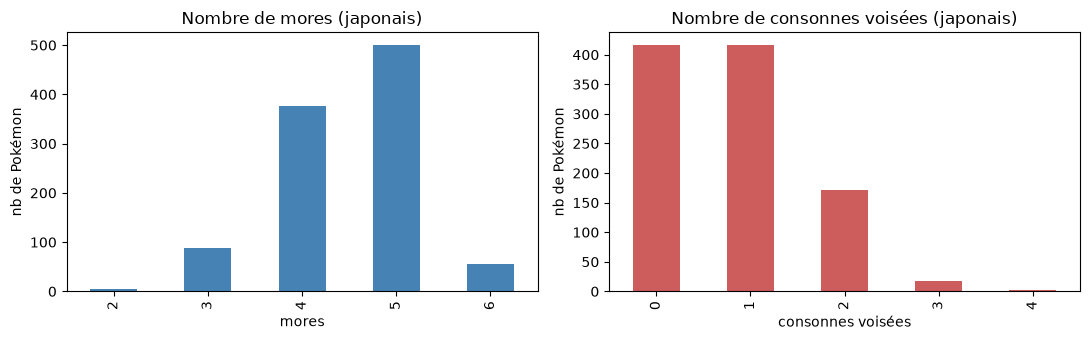

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
noms["ja_mores"].value_counts().sort_index().plot.bar(ax=axes[0], color="steelblue")
axes[0].set(title="Nombre de mores (japonais)", xlabel="mores", ylabel="nb de Pokémon")
noms["ja_voisees"].value_counts().sort_index().plot.bar(ax=axes[1], color="indianred")
axes[1].set(title="Nombre de consonnes voisées (japonais)", xlabel="consonnes voisées", ylabel="nb de Pokémon")
plt.tight_layout()

### Ce qu'on a fait et pourquoi

**1. Partir des kana plutôt que du romaji.** On a codé les noms japonais à partir des kana parce que c'est ce qu'a fait Kawahara (on peut donc comparer avec son résultat) et parce que les kana suivent la prononciation, alors que le romaji n'est pas toujours écrit pareil.

**2. Compter des mores.** La more, c'est l'unité de rythme du japonais, donc c'est la bonne mesure de la longueur d'un nom japonais (bien mieux que le nombre de caractères). On a collé les petits kana (ャ, ュ, ョ…) au kana d'avant parce qu'ils se prononcent avec lui, sauf quand un petit kana voyelle répète la voyelle d'avant : là il l'allonge et compte comme une more (ピィ = « pii »). Pour trouver la voyelle d'un kana, on lit son nom Unicode (« KATAKANA LETTER PI » se termine par I), ce qui évite une table à la main.

**3. Compter les consonnes voisées avec le ゛.** En décomposant chaque kana avec Unicode, ガ devient カ + ゛, et il suffit de compter les ゛. C'est simple, sans liste à la main, et c'est exactement la définition de Kawahara (on ne compte pas le ゜, qui donne un « p », non voisé).

**4. Les diagrammes en barres.** Mores et consonnes voisées sont des petits nombres entiers (de 0 à 6), donc un diagramme en barres montre directement combien de Pokémon il y a pour chaque valeur. Un histogramme avec des classes n'aurait rien apporté de plus.

## 3. Les variables sonores du français et de l'anglais

Pour le français (et l'anglais, qu'on ajoute parce que c'est le nom que voient les votants anglophones, voir la partie 7), **l'orthographe n'est pas la prononciation** : le « s » de Rosélia se prononce z, le « x » de Ronflex se prononce ks, le c de Carapuce est dur puis doux, beaucoup de lettres finales sont muettes. Une première version de ce notebook codait les sons à partir des lettres, avec ces erreurs.

On passe donc par une **transcription phonétique automatique** avec **espeak-ng**, un logiciel de synthèse vocale libre qui transforme un mot écrit en sons, notés en **alphabet phonétique international (API)**. Il sait prononcer des mots inventés en appliquant les règles de prononciation de la langue, ce qui est exactement notre cas. Il n'est pas parfait sur des noms inventés : on vérifie donc un échantillon à la main.

Ensuite, on compte des **sons** et plus des lettres :
- **syllabes** : une par voyelle prononcée (une diphtongue comme « aï » compte pour une) ;
- **consonnes voisées** : b, d, g, v, z, ʒ (le « j » de « joue »), ð, dʒ (le « dj ») ;
- **occlusives** (sons « durs », qui claquent) : p, t, k, b, d, g, et tʃ, dʒ ;
- **sonantes** (sons « doux ») : m, n, l, r et leurs variantes.

espeak-ng doit être installé sur la machine (`sudo apt install espeak-ng`).

In [11]:
VOIX = {"fr": "fr", "en": "en-us"}

def transcrire(nom, langue):
    # on enlève les symboles qu'espeak lirait en toutes lettres (« female sign » pour ♀)
    propre = re.sub(r"[♀♂:.]", " ", nom)
    sortie = subprocess.run(["espeak-ng", "-q", "--ipa", "-v", VOIX[langue], propre],
                            capture_output=True, text=True, check=True).stdout
    sortie = re.sub(r"\([a-z-]+\)", "", sortie)   # marqueurs quand espeak change de langue, ex. (en)
    return re.sub(r"\s+", " ", sortie).strip()

VOYELLES_API = set("aeiouyæɐɑɒɔəɘɛɜɚɝɞɤɨɪɯɵøœɶʉʊʌʏᵻ")
DIPHTONGUES = ("aɪ", "aʊ", "eɪ", "oʊ", "ɔɪ")
VOISEES_API = {"b", "d", "ɡ", "v", "z", "ʒ", "ð", "dʒ"}
OCCLUSIVES_API = {"p", "t", "k", "b", "d", "ɡ", "tʃ", "dʒ", "ɾ"}   # ɾ : le « t » américain de Ponyta
SONANTES_API = {"m", "n", "ɲ", "ŋ", "l", "ɹ", "ʁ", "r", "n̩"}

def phonemes(api):
    s = unicodedata.normalize("NFC", re.sub(r"[ˈˌː\s-]", "", api))
    sons, i = [], 0
    while i < len(s):
        deux = s[i:i + 2]
        if deux in ("tʃ", "dʒ") or deux in DIPHTONGUES:
            sons.append(deux); i += 2
        else:
            sons.append(s[i]); i += 1
        while i < len(s) and unicodedata.combining(s[i]):   # nasales (ɔ̃), n syllabique (n̩)…
            sons[-1] += s[i]; i += 1
    # espeak double parfois une consonne (Charizard : ɹɹ) : on ne la compte qu'une fois
    return [t for k, t in enumerate(sons) if not (k and t == sons[k - 1] and t[0] not in VOYELLES_API)]

def variables_sons(api):
    sons = phonemes(api)
    return {"phonemes": len(sons),
            "syllabes": max(sum(t[0] in VOYELLES_API or t == "n̩" for t in sons), 1),
            "voisees": sum(t in VOISEES_API for t in sons),
            "occlusives": sum(t in OCCLUSIVES_API for t in sons),
            "sonantes": sum(t in SONANTES_API for t in sons)}

for langue, col in [("fr", "nom_fr"), ("en", "nom_en")]:
    api = table[col].map(lambda n: transcrire(n, langue))
    v = pd.DataFrame(api.map(variables_sons).tolist(), index=table.index).add_prefix(langue + "_")
    noms[langue + "_api"] = api
    noms = noms.join(v)
    for c in ["voisees", "occlusives", "sonantes"]:
        noms[f"{langue}_{c}_part"] = noms[f"{langue}_{c}"] / noms[f"{langue}_phonemes"]
noms["fr_lettres"] = table["nom_fr"].map(lambda s: len(re.sub(r"[^a-z]", "", sans_accents(s).lower())))
print("transcriptions vides :", (noms[["fr_api", "en_api"]] == "").sum().to_dict())
noms.filter(regex="^(fr|en)_(syllabes|voisees|occlusives|sonantes|phonemes)$").describe().T.round(2)

transcriptions vides : {'fr_api': 0, 'en_api': 0}


,count,mean,std,min,25%,50%,75%,max
fr_phonemes,1025.0,6.94,1.38,2.0,6.0,7.0,8.0,11.0
fr_syllabes,1025.0,2.88,0.67,1.0,2.0,3.0,3.0,5.0
fr_voisees,1025.0,0.80,0.83,0.0,0.0,1.0,1.0,4.0
fr_occlusives,1025.0,1.52,0.96,0.0,1.0,1.0,2.0,5.0
fr_sonantes,1025.0,1.58,0.91,0.0,1.0,2.0,2.0,4.0
en_phonemes,1025.0,6.73,1.47,3.0,6.0,7.0,8.0,12.0
en_syllabes,1025.0,2.66,0.75,1.0,2.0,3.0,3.0,5.0
en_voisees,1025.0,0.80,0.80,0.0,0.0,1.0,1.0,4.0
en_occlusives,1025.0,1.61,0.97,0.0,1.0,2.0,2.0,5.0
en_sonantes,1025.0,1.60,0.88,0.0,1.0,2.0,2.0,5.0


In [12]:
# les cas difficiles cités plus haut, et ce que donnait le codage par lettres pour les consonnes voisées
pieges = table.loc[[315, 143, 4, 7, 1, 6, 122, 29], ["nom_fr"]].copy()
pieges["api"] = noms["fr_api"]
pieges["voisees_lettres"] = pieges["nom_fr"].map(lambda s: sum(sans_accents(s).lower().count(c) for c in "bdgvzj"))
pieges["voisees_sons"] = noms["fr_voisees"]
pieges["syllabes_sons"] = noms["fr_syllabes"]
pieges

,nom_fr,api,voisees_lettres,voisees_sons,syllabes_sons
dex,,,,,
315,Rosélia,ʁozeljˈa,0,1,3
143,Ronflex,ʁɔ̃flˈɛks,0,0,2
4,Salamèche,salamˈɛʃ,0,0,3
7,Carapuce,kaʁapˈys,0,0,3
1,Bulbizarre,bylbizˈaʁ,3,3,3
6,Dracaufeu,dʁakofˈø,1,1,3
122,M. Mime,ˈɛm mˈim,0,0,2
29,Nidoran♀,nidoʁˈɑ̃,1,1,3


Sur les cas difficiles, la transcription règle les erreurs du codage par lettres : le s de Rosélia devient bien un **z** (`ʁozeljˈa`, une consonne voisée que les lettres ne voyaient pas), le x de Ronflex devient **ks**, les lettres muettes disparaissent (Salamèche → `salamˈɛʃ`), et M. Mime est lu « aime mime ». Sur les 1 025 noms français, le nouveau codage change le nombre de syllabes pour 16 % des noms et le nombre de consonnes voisées pour 10 %.

In [13]:
# validation : un échantillon au hasard dans chaque langue, qu'on relit à la main
pd.set_option("display.max_rows", 40)
ech = []
for langue, col in [("fr", "nom_fr"), ("en", "nom_en")]:
    e = table[[col]].rename(columns={col: "nom"}).sample(15, random_state=4)
    e["langue"] = langue
    e["api"] = noms.loc[e.index, langue + "_api"]
    for c in ["syllabes", "voisees", "occlusives", "sonantes"]:
        e[c] = noms.loc[e.index, f"{langue}_{c}"]
    ech.append(e)
pd.concat(ech)[["langue", "nom", "api", "syllabes", "voisees", "occlusives", "sonantes"]]

,langue,nom,api,syllabes,voisees,occlusives,sonantes
dex,,,,,,,
933,fr,Amassel,amasˈɛl,3,0,0,2
77,fr,Ponyta,ponitˈa,3,0,2,1
354,fr,Branette,bʁanˈɛt,2,1,2,2
622,fr,Gringolem,ɡʁɛ̃ɡolˈɛm,3,2,2,3
831,fr,Moumouton,mumutˈɔ̃,3,0,1,2
216,fr,Teddiursa,tɛdjyʁsˈa,3,1,2,1
739,fr,Crabagarre,kʁabaɡˈaʁ,3,2,3,2
885,fr,Fantyrm,fɑ̃tˈiʁm,2,0,1,2
981,fr,Farigiraf,faʁiʒiʁˈaf,4,1,0,2


On a relu cet échantillon à la main. La grande majorité des transcriptions sont justes, y compris sur des noms difficiles (Basculegion, Gringolem, Paragruel, Farigiraf). Les erreurs qu'on repère :
- espeak reconnaît parfois un nom français comme un mot anglais et le lit à l'anglaise (Lewsor → `lˈuːsə`, Parecool) : ça reste une prononciation possible, mais pas celle d'un enfant français ;
- sur quelques noms inventés, la prononciation choisie n'est pas celle du dessin animé (Gengar est lu avec un « dj », alors qu'on dit « Guen-gar »), ce qui ajoute ou enlève parfois une consonne voisée ;
- quelques découpages de voyelles discutables (Teddiursa en 3 syllabes en français).

Ces erreurs sont rares et ne vont pas toujours dans le même sens : elles ajoutent du bruit, ce qui peut affaiblir un peu les liens, mais pas en créer de faux.

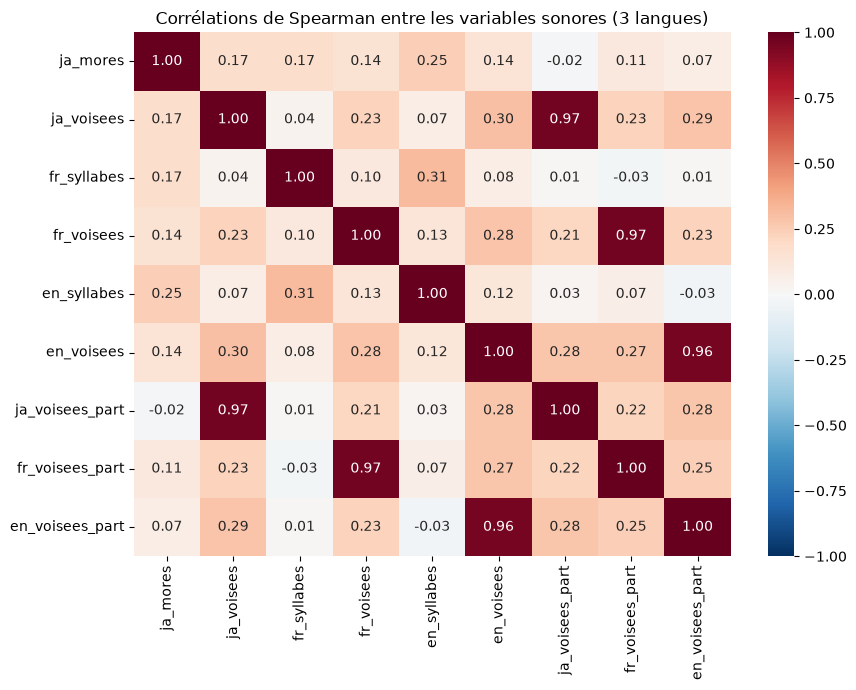

In [14]:
# les variables sont-elles liées entre elles, et d'une langue à l'autre ? (Spearman)
cols_heat = ["ja_mores", "ja_voisees", "fr_syllabes", "fr_voisees", "en_syllabes", "en_voisees",
             "ja_voisees_part", "fr_voisees_part", "en_voisees_part"]
plt.figure(figsize=(9, 7))
sns.heatmap(noms[cols_heat].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Corrélations de Spearman entre les variables sonores (3 langues)")
plt.tight_layout()

Comme en japonais, les variables « en nombre » et « en proportion » sont très liées (0,96-0,97). Plus intéressant : **les trois noms d'un même Pokémon se ressemblent peu**. La longueur japonaise et la longueur française ne sont liées qu'à 0,17, la française et l'anglaise à 0,31 ; pour les consonnes voisées, c'est entre 0,23 et 0,30. Les noms français et anglais ne sont donc pas des traductions du japonais : ce sont souvent des noms inventés à part, d'où l'intérêt de tester les trois langues.

### Ce qu'on a fait et pourquoi

**1. Une transcription phonétique plutôt que l'orthographe.** Une première version codait les sons à partir des lettres, avec des erreurs connues (le s de Rosélia, le x de Ronflex, les lettres muettes). On passe par espeak-ng, qui transforme un mot en sons avec les règles de prononciation de chaque langue, même pour des mots inventés. Ça nous permet aussi d'ajouter l'anglais avec exactement la même méthode.

**2. Compter des sons, pas des lettres.** Une syllabe = une voyelle prononcée (une diphtongue compte pour une), et les familles de consonnes (voisées, occlusives, sonantes) sont définies sur les sons de l'alphabet phonétique. Avant de compter, on a fait l'inventaire de tous les symboles produits par espeak sur les 2 050 noms, pour être sûr qu'aucun n'était mal rangé (c'est comme ça qu'on a repéré la voyelle réduite ᵻ et le « t » américain ɾ).

**3. Vérifier à la main.** Une transcription automatique se trompe forcément sur des noms inventés. On a donc regardé les cas difficiles connus et un échantillon au hasard de 15 noms par langue, pour savoir quel genre d'erreurs elle fait et à quelle fréquence.

**4. Des variables en proportion.** Comme en japonais, un nom long a forcément plus de consonnes de chaque sorte : on calcule aussi chaque variable en proportion du nombre de sons, pour ne pas mesurer la longueur une deuxième fois.

## 4. Retrouver le résultat de Kawahara (japonais)

On calcule la corrélation de Spearman entre les variables sonores et la taille, le poids, le total des stats et le stade d'évolution.

Pour le **stade**, on enlève les Pokémon « sans évolution » (la catégorie à part du notebook 01) : pour eux le stade ne veut rien dire, et ce sont souvent des légendaires très forts qui brouilleraient le lien. On les garde par contre pour la taille, le poids et les stats, qui ont du sens pour tout le monde.

La **p-valeur** dit si la corrélation pourrait être due au hasard : en dessous de 0,05 on considère en général que le lien est significatif. Avec 1 025 Pokémon, même une petite corrélation (0,1) devient significative, donc il faut regarder la **force** du rho et pas seulement la p-valeur.

In [15]:
def spearman_table(variables, cibles, data):
    lignes = []
    for v in variables:
        for c in cibles:
            d = data[[v, c]].dropna()
            rho, p = spearmanr(d[v], d[c])
            lignes.append({"variable": v, "cible": c, "rho": round(rho, 3), "p_valeur": p, "n": len(d)})
    return pd.DataFrame(lignes)

data = noms.join(table[["taille_m", "poids_kg", "total_stats", "stade", "stade_categorie", "generation"]])
data["stade_si_evolution"] = data["stade"].where(data["stade_categorie"] != "sans évolution")

cibles_physiques = ["taille_m", "poids_kg", "total_stats", "stade_si_evolution"]
res_ja = spearman_table(["ja_mores", "ja_voisees", "ja_voisees_part"], cibles_physiques, data)
res_ja.pivot(index="variable", columns="cible", values="rho")

cible,poids_kg,stade_si_evolution,taille_m,total_stats
variable,,,,
ja_mores,0.364,0.437,0.400,0.422
ja_voisees,0.265,0.205,0.241,0.194
ja_voisees_part,0.195,0.116,0.161,0.104


In [16]:
res_ja

,variable,cible,rho,p_valeur,n
0,ja_mores,taille_m,0.400,1.012016e-40,1025
1,ja_mores,poids_kg,0.364,1.871248e-33,1025
2,ja_mores,total_stats,0.422,1.703766e-45,1025
3,ja_mores,stade_si_evolution,0.437,8.441617e-40,824
4,ja_voisees,taille_m,0.241,4.825773e-15,1025
5,ja_voisees,poids_kg,0.265,7.151104e-18,1025
6,ja_voisees,total_stats,0.194,3.873118e-10,1025
7,ja_voisees,stade_si_evolution,0.205,3.084298e-09,824
8,ja_voisees_part,taille_m,0.161,2.072728e-07,1025
9,ja_voisees_part,poids_kg,0.195,3.069132e-10,1025


On retrouve bien le résultat de Kawahara en japonais :
- plus le nom a de **mores**, plus le Pokémon est grand (rho = 0,40), lourd (0,36), fort (0,42) et évolué (0,44) ;
- plus il a de **consonnes voisées**, plus il est lourd (0,27) et grand (0,24), et un peu plus fort (0,19) et évolué (0,21).

Toutes les p-valeurs sont très petites (en dessous de 0,001). Le lien le plus fort, c'est la **longueur** du nom. En proportion de la longueur, l'effet des consonnes voisées reste là mais il est plus faible (0,16 à 0,20 pour la taille et le poids).

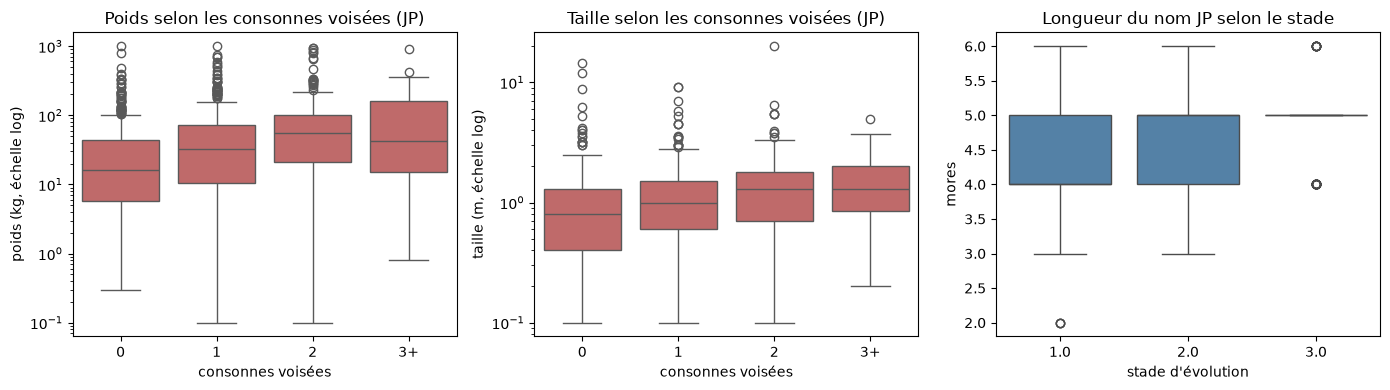

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
data["voisees_cl"] = data["ja_voisees"].clip(upper=3).map(lambda x: "3+" if x == 3 else str(x))
ordre = ["0", "1", "2", "3+"]
sns.boxplot(data=data, x="voisees_cl", y="poids_kg", order=ordre, ax=axes[0], color="indianred")
axes[0].set(yscale="log", title="Poids selon les consonnes voisées (JP)", xlabel="consonnes voisées", ylabel="poids (kg, échelle log)")
sns.boxplot(data=data, x="voisees_cl", y="taille_m", order=ordre, ax=axes[1], color="indianred")
axes[1].set(yscale="log", title="Taille selon les consonnes voisées (JP)", xlabel="consonnes voisées", ylabel="taille (m, échelle log)")
sns.boxplot(data=data.dropna(subset=["stade_si_evolution"]), x="stade_si_evolution", y="ja_mores", ax=axes[2], color="steelblue")
axes[2].set(title="Longueur du nom JP selon le stade", xlabel="stade d'évolution", ylabel="mores")
plt.tight_layout()

Sur les boxplots, le poids médian passe de 16 kg (aucune consonne voisée) à 32,5 kg (une) puis 55 kg (deux), et la taille médiane de 0,8 m à 1,3 m. Pour 3 voisées ou plus le poids redescend un peu (42 kg), mais il y a très peu de noms dans ce groupe. Et les noms s'allongent bien d'un stade à l'autre.

### Ce qu'on a fait et pourquoi

**1. La corrélation de Spearman (TP1).** Pour retrouver Kawahara, on compare les variables sonores à la taille, au poids, aux stats et au stade. On a pris Spearman parce que le poids et la taille ont des valeurs extrêmes énormes (des Pokémon de quelques grammes et d'autres de plusieurs centaines de kilos) : Pearson serait tiré par ces quelques Pokémon. Spearman travaille sur les rangs, donc il est insensible à ça, et il ne suppose pas que le lien est une droite.

**2. Regarder le rho, pas seulement la p-valeur.** Avec 1 025 Pokémon, même un lien minuscule devient « significatif ». Du coup on lit d'abord la force du lien (le rho), et la p-valeur sert juste à vérifier que ce n'est pas du hasard.

**3. Enlever les « sans évolution » pour le stade.** Pour eux, le stade ne veut rien dire, et ce sont souvent des légendaires très forts qui auraient brouillé le lien entre la longueur du nom et l'évolution. On les a gardés pour la taille, le poids et les stats, qui ont du sens pour tout le monde.

**4. Les boxplots avec une échelle log.** Pour montrer le lien entre consonnes voisées et poids, on a fait un boxplot par nombre de voisées : on voit la médiane et l'étalement de chaque groupe, ce qui est plus lisible qu'un nuage de 1 025 points sur des valeurs entières. L'axe du poids et de la taille est en échelle log, sinon les quelques Pokémon énormes écraseraient toutes les boîtes en bas du graphique. On a regroupé « 3 et plus » parce que ces groupes sont tout petits.

## 5. Et en français, et en anglais ?

Même méthode qu'en japonais : Spearman entre les variables sonores et la taille, le poids, les stats et le stade.

In [18]:
vars_fr = ["fr_syllabes", "fr_voisees", "fr_voisees_part", "fr_occlusives_part", "fr_sonantes_part"]
vars_en = ["en_syllabes", "en_voisees", "en_voisees_part", "en_occlusives_part", "en_sonantes_part"]
res_fr_en = spearman_table(vars_fr + vars_en, cibles_physiques, data.join(noms[[c for c in vars_fr + vars_en if c not in data]]))
res_fr_en.pivot(index="variable", columns="cible", values="rho")

cible,poids_kg,stade_si_evolution,taille_m,total_stats
variable,,,,
en_occlusives_part,-0.077,-0.094,-0.098,-0.152
en_sonantes_part,0.100,0.068,0.033,0.083
en_syllabes,0.182,0.262,0.231,0.290
en_voisees,0.126,0.095,0.151,0.092
en_voisees_part,0.085,0.030,0.100,0.033
fr_occlusives_part,-0.035,-0.067,-0.049,-0.102
fr_sonantes_part,0.061,0.116,0.044,0.050
fr_syllabes,0.070,0.136,0.083,0.124
fr_voisees,0.100,0.080,0.099,0.083


En **anglais**, on retrouve le même sens qu'en japonais, plus faiblement : plus le nom a de syllabes, plus le Pokémon est fort (0,29), évolué (0,26), grand (0,23) et lourd (0,18) ; les consonnes voisées vont avec un Pokémon un peu plus grand et lourd (0,13 à 0,15). Les sons « durs » (occlusives), eux, vont plutôt avec des Pokémon un peu **moins** forts (-0,15).

En **français**, c'est encore plus faible : la longueur va avec le stade (0,14) et les stats (0,12), les consonnes voisées avec la taille et le poids (0,10). Tout va dans le même sens que le japonais, mais les rho restent autour de 0,1, un lien presque invisible même s'il est « significatif » avec 1 025 Pokémon. La transcription phonétique ne change presque rien par rapport au codage par lettres : le lien faible ne venait donc pas surtout de notre codage.

L'ordre est clair : **japonais > anglais > français**. Ça colle avec l'idée que les noms japonais sont les noms d'origine, pensés avec cette symbolique, et que les traductions la gardent plus ou moins.

### Ce qu'on a fait et pourquoi

**1. La même méthode dans les trois langues.** Mêmes cibles, même Spearman, mêmes variables : si une langue donne des liens plus faibles, ça ne vient pas d'une méthode différente.

**2. Comparer les tailles d'effet.** Avec 1 025 Pokémon, beaucoup de liens passent sous p = 0,05 avec des rho autour de 0,1. On compare donc les rho d'une langue à l'autre plutôt que de compter les liens « significatifs ».

## 6. Dans une même lignée : le nom grandit-il avec l'évolution ?

Les corrélations ci-dessus comparent tous les Pokémon entre eux, ce qui mélange des Pokémon qui n'ont rien à voir (types, générations, designs différents). L'idée de Kawahara est plus précise : **quand un Pokémon évolue, son nom s'allonge et se durcit**. La façon la plus propre de le tester, c'est de comparer chaque Pokémon **à sa propre pré-évolution** (Salamèche → Reptincel, Reptincel → Dracaufeu) : dans une paire, tout le reste est à peu près pareil.

Pour chaque paire, on regarde si l'évolution a **plus**, **moins** ou **autant** de syllabes (de mores en japonais) et de consonnes voisées. Si le nom n'avait rien à voir avec l'évolution, « plus » et « moins » seraient aussi fréquents : c'est ce que vérifie le **test du signe** (un test binomial sur les paires où il y a une différence).

In [19]:
especes = pd.read_csv(Path("../data/raw/pokeapi/pokemon_species.csv"), index_col="id")
paires = especes["evolves_from_species_id"].dropna().astype(int)
paires = pd.DataFrame({"evolution": paires.index, "pre_evolution": paires.values})
print("paires d'évolution :", len(paires))

lignes = []
for langue, variables in [("japonais", ["ja_mores", "ja_voisees"]), ("français", ["fr_syllabes", "fr_voisees"]),
                          ("anglais", ["en_syllabes", "en_voisees"])]:
    for v in variables:
        diff = noms.loc[paires.evolution, v].values - noms.loc[paires.pre_evolution, v].values
        plus, moins = int((diff > 0).sum()), int((diff < 0).sum())
        lignes.append({"langue": langue, "variable": v, "évolution a plus": plus, "évolution a moins": moins,
                       "égal": int((diff == 0).sum()), "part de plus (hors égalités)": round(plus / (plus + moins), 2),
                       "p_valeur": binomtest(plus, plus + moins).pvalue})
lignees = pd.DataFrame(lignes)
lignees["p_valeur"] = lignees["p_valeur"].map(lambda p: f"{p:.1e}")
lignees

paires d'évolution : 484


,langue,variable,évolution a plus,évolution a moins,égal,part de plus (hors égalités),p_valeur
0,japonais,ja_mores,248,27,209,0.90,6.6e-46
1,japonais,ja_voisees,167,68,249,0.71,8.6e-11
2,français,fr_syllabes,133,67,284,0.67,3.5e-06
3,français,fr_voisees,147,112,225,0.57,3.4e-02
4,anglais,en_syllabes,188,61,235,0.76,3.1e-16
5,anglais,en_voisees,153,103,228,0.60,2.1e-03


In [20]:
# un exemple de lignée dans les trois langues
for lignee in [(4, 5, 6), (1, 2, 3), (133, 134), (172, 25, 26)]:
    print(" → ".join(f"{table.nom_fr[d]} / {table.nom_en[d]} / {table.nom_ja[d]}" for d in lignee))
    print("   syllabes FR", [noms.fr_syllabes[d] for d in lignee], "| EN", [noms.en_syllabes[d] for d in lignee],
          "| mores JP", [noms.ja_mores[d] for d in lignee])

Salamèche / Charmander / ヒトカゲ → Reptincel / Charmeleon / リザード → Dracaufeu / Charizard / リザードン
   syllabes FR [np.int64(3), np.int64(3), np.int64(3)] | EN [np.int64(3), np.int64(4), np.int64(3)] | mores JP [np.int64(4), np.int64(4), np.int64(5)]
Bulbizarre / Bulbasaur / フシギダネ → Herbizarre / Ivysaur / フシギソウ → Florizarre / Venusaur / フシギバナ
   syllabes FR [np.int64(3), np.int64(3), np.int64(3)] | EN [np.int64(3), np.int64(3), np.int64(3)] | mores JP [np.int64(5), np.int64(5), np.int64(5)]
Évoli / Eevee / イーブイ → Aquali / Vaporeon / シャワーズ
   syllabes FR [np.int64(3), np.int64(3)] | EN [np.int64(2), np.int64(4)] | mores JP [np.int64(4), np.int64(4)]
Pichu / Pichu / ピチュー → Pikachu / Pikachu / ピカチュウ → Raichu / Raichu / ライチュウ
   syllabes FR [np.int64(2), np.int64(3), np.int64(2)] | EN [np.int64(2), np.int64(3), np.int64(2)] | mores JP [np.int64(3), np.int64(4), np.int64(4)]


**Dans les trois langues, le nom grandit avec l'évolution.** Sur les 484 paires d'évolution :
- en **japonais**, l'évolution a plus de mores que sa pré-évolution dans **90 %** des paires où il y a une différence (248 contre 27), et plus de consonnes voisées dans 71 % (167 contre 68) ;
- en **anglais**, plus de syllabes dans **76 %** des cas (188 contre 61), plus de voisées dans 60 % ;
- en **français**, plus de syllabes dans **67 %** des cas (133 contre 67, p < 0,001), plus de voisées dans 57 % (p = 0,03).

C'est le résultat le plus net du notebook. En français, les corrélations globales trouvaient un lien presque invisible (0,14 avec le stade) : en comparant dans une même lignée, l'effet apparaît clairement. Le calcul global était noyé par toutes les différences entre Pokémon qui n'ont rien à voir avec le nom ; la comparaison par paires les enlève.

Beaucoup de paires ont la **même** longueur (de 209 à 284 selon la langue), comme Bulbizarre → Herbizarre → Florizarre : l'effet est une tendance, pas une règle. Et le japonais reste de loin le plus marqué, comme dans les corrélations.

### Ce qu'on a fait et pourquoi

**1. Comparer chaque Pokémon à sa pré-évolution.** C'est le test le plus proche de l'idée de Kawahara (« le nom change quand le Pokémon évolue »), et le plus propre : dans une paire, le type, la génération et le design sont presque les mêmes, donc ils ne peuvent pas créer un faux lien. Les paires viennent directement de PokéAPI (`evolves_from_species_id`).

**2. Le test du signe.** On ne regarde que le sens de la différence (plus, moins, égal), pas sa taille : une more de plus, c'est déjà un nom plus long. Si le nom ne dépendait pas de l'évolution, « plus » et « moins » seraient aussi fréquents ; le test du signe (un test binomial sur les paires qui diffèrent) dit si l'écart observé peut venir du hasard. C'est un test très simple et sans hypothèse sur la distribution.

**3. Garder les égalités visibles.** On affiche le nombre de paires à égalité : beaucoup de lignées gardent la même longueur, et le dire évite de présenter l'effet comme une règle absolue.

## 7. Le son du nom et la popularité

**Qui voit quel nom ?** C'est la question à se poser avant de chercher un lien entre le son d'un nom et la popularité :
- **Reddit 2019** et **Johto Times 2025** sont des publics **anglophones** : ils votent pour « Charizard », pas pour « Dracaufeu » ni « リザードン ». Si le son du nom joue sur ce qu'on aime, c'est le **nom anglais** qui compte pour eux ;
- **Pokémon of the Year 2020** est un vote **mondial et multilingue** : chaque votant a vu le nom dans sa langue. On ne sait pas combien de votants par langue, donc on teste nos trois langues, en sachant que l'effet est forcément dilué.

Les noms japonais et français gardent un intérêt même face à un public anglophone, mais pour une autre question : **les noms qui « annoncent » un Pokémon gros ou fort vont-ils avec des Pokémon plus aimés ?** C'est alors une question sur l'intention des concepteurs, pas sur ce que les votants entendent.

Pour la popularité, on reprend les percentiles **dans la génération** du notebook 02 (comme les autres notebooks), et pas un percentile global : les noms s'allongent au fil des générations, et les générations récentes sont moins aimées, donc un percentile global mélangerait l'effet du nom et celui de la génération.

Comme on fait beaucoup de tests, on corrige les p-valeurs pour les **tests multiples** avec la méthode de **Holm** : sur 30 tests au seuil de 5 %, on s'attendrait à 1 ou 2 résultats « significatifs » par pur hasard. Holm rend chaque test plus exigeant pour que la famille de tests garde au total moins de 5 % de risque de fausse alerte.

In [21]:
sources_pop = {"reddit": "reddit_pct_gen", "johto": "johto_pct_gen"}
data = data.join(noms[[c for c in noms.columns if c not in data and not c.endswith("_api")]])
data = data.join(pop_sources[["reddit_pct_gen", "johto_pct_gen", "poty_pct_gen"]])
data = data.join(table[["legendaire", "fabuleux"]])

def avec_holm(res):
    res = res.copy()
    res["p_holm"] = multipletests(res["p_valeur"], method="holm")[1]
    res["significatif"] = np.where(res["p_holm"] < 0.05, "oui", "")
    return res

vars_pop = ["en_syllabes", "en_voisees", "en_voisees_part", "en_occlusives_part", "en_sonantes_part",
            "ja_mores", "ja_voisees", "fr_syllabes", "fr_voisees"]
res_pop = avec_holm(spearman_table(vars_pop, list(sources_pop.values()), data))
res_pop.assign(p_valeur=res_pop.p_valeur.round(3), p_holm=res_pop.p_holm.round(3))

,variable,cible,rho,p_valeur,n,p_holm,significatif
0,en_syllabes,reddit_pct_gen,0.052,0.137,809,1.000,
1,en_syllabes,johto_pct_gen,0.114,0.000,1025,0.004,oui
2,en_voisees,reddit_pct_gen,-0.009,0.800,809,1.000,
3,en_voisees,johto_pct_gen,-0.020,0.521,1025,1.000,
4,en_voisees_part,reddit_pct_gen,-0.007,0.844,809,1.000,
5,en_voisees_part,johto_pct_gen,-0.028,0.364,1025,1.000,
6,en_occlusives_part,reddit_pct_gen,-0.059,0.092,809,1.000,
7,en_occlusives_part,johto_pct_gen,-0.115,0.000,1025,0.004,oui
8,en_sonantes_part,reddit_pct_gen,0.000,0.996,809,1.000,
9,en_sonantes_part,johto_pct_gen,0.008,0.786,1025,1.000,


Tous stades confondus, après la correction de Holm, il ne reste que **deux liens, tous les deux faibles et seulement au Johto Times** : les noms anglais plus longs sont un peu plus aimés (rho = 0,11), et les noms anglais avec plus de sons « durs » un peu moins (-0,12). Rien sur Reddit. Les noms japonais et français ne sont liés à rien une fois la correction faite (le lien voisées JP ↔ Reddit, p = 0,008 avant correction, ne tient pas).

Le lien « nom anglais long ↔ plus aimé » passe sans doute par le stade : les formes évoluées ont des noms plus longs (partie 6) et sont plus aimées (notebook 05). On le vérifie juste en dessous, à stade égal.

In [22]:
# à stade égal, avec et sans les légendaires et fabuleux
lignes = []
for groupe, dd in [("tous", data), ("sans légendaires ni fabuleux", data[~(data.legendaire | data.fabuleux)])]:
    for stade, d in dd.groupby("stade_categorie"):
        for v in ["en_syllabes", "en_voisees", "ja_mores", "fr_syllabes"]:
            for c in sources_pop.values():
                z = d[[v, c]].dropna()
                rho, p = spearmanr(z[v], z[c])
                lignes.append({"groupe": groupe, "stade": stade, "variable": v, "cible": c, "rho": round(rho, 3), "p_valeur": p, "n": len(z)})
par_stade = pd.DataFrame(lignes)
# correction de Holm séparément pour chaque groupe (tous / sans légendaires)
par_stade = pd.concat([avec_holm(g) for _, g in par_stade.groupby("groupe")])
par_stade.pivot_table(index=["variable", "cible"], columns=["groupe", "stade"], values="rho").round(2)

groupe                     sans légendaires ni fabuleux                  \
stade                                    sans évolution stade 1 stade 2   
variable    cible                                                         
en_syllabes johto_pct_gen                         -0.04   -0.10    0.14   
            reddit_pct_gen                        -0.07   -0.15    0.05   
en_voisees  johto_pct_gen                         -0.23   -0.12    0.00   
            reddit_pct_gen                        -0.00   -0.09   -0.03   
fr_syllabes johto_pct_gen                         -0.13    0.05    0.01   
            reddit_pct_gen                        -0.03    0.02   -0.03   
ja_mores    johto_pct_gen                         -0.29   -0.22    0.07   
            reddit_pct_gen                        -0.20   -0.10    0.00   

groupe                                       tous                          
stade                      stade 3 sans évolution stade 1 stade 2 stade 3  
variable    cible                                                          
en_syllabes johto_pct_gen     0.17          -0.09   -0.11    0.14    0.18  
            reddit_pct_gen    0.15          -0.11   -0.15    0.05    0.13  
en_voisees  johto_pct_gen     0.04          -0.07   -0.12   -0.01    0.03  
            reddit_pct_gen   -0.04           0.06   -0.08   -0.03   -0.03  
fr_syllabes johto_pct_gen     0.16          -0.16    0.04    0.01    0.16  
            reddit_pct_gen    0.09          -0.06    0.03   -0.03    0.07  
ja_mores    johto_pct_gen     0.14          -0.32   -0.21    0.06    0.14  
            reddit_pct_gen    0.02          -0.23   -0.09   -0.00    0.01

In [23]:
# ce qui reste significatif après la correction de Holm
par_stade[par_stade.p_valeur < 0.05].assign(p_valeur=lambda x: x.p_valeur.round(4), p_holm=lambda x: x.p_holm.round(4)) \
    .sort_values(["groupe", "stade"])[["groupe", "stade", "variable", "cible", "rho", "n", "p_valeur", "p_holm", "significatif"]]

,groupe,stade,variable,cible,rho,n,p_valeur,p_holm,significatif
35,sans légendaires ni fabuleux,sans évolution,en_voisees,johto_pct_gen,-0.232,117,0.0119,0.3460,
37,sans légendaires ni fabuleux,sans évolution,ja_mores,johto_pct_gen,-0.288,117,0.0017,0.0515,
40,sans légendaires ni fabuleux,stade 1,en_syllabes,reddit_pct_gen,-0.149,279,0.0130,0.3627,
43,sans légendaires ni fabuleux,stade 1,en_voisees,johto_pct_gen,-0.124,336,0.0235,0.6356,
45,sans légendaires ni fabuleux,stade 1,ja_mores,johto_pct_gen,-0.217,336,0.0001,0.0020,oui
49,sans légendaires ni fabuleux,stade 2,en_syllabes,johto_pct_gen,0.144,359,0.0064,0.1910,
4,tous,sans évolution,ja_mores,reddit_pct_gen,-0.234,139,0.0056,0.1666,
5,tous,sans évolution,ja_mores,johto_pct_gen,-0.315,201,0.0000,0.0002,oui
7,tous,sans évolution,fr_syllabes,johto_pct_gen,-0.164,201,0.0197,0.5308,
8,tous,stade 1,en_syllabes,reddit_pct_gen,-0.148,282,0.0130,0.3644,


À stade égal, la plupart des liens disparaissent après la correction de Holm (dont le lien « nom anglais long ↔ plus aimé », qui passait donc par le stade). **Un seul résultat tient, et seulement au Johto Times : chez les stades 1 et les Pokémon sans évolution, un nom japonais long va avec un Pokémon moins aimé** (rho de -0,21 à -0,32).

Le contrôle sans légendaires répond au doute qu'on avait : le lien en japonais **tient** sans les légendaires et fabuleux (-0,22 chez les stades 1, p corrigé = 0,002 ; -0,29 chez les sans évolution, p corrigé = 0,05, juste à la limite). En français, le lien qu'on voyait chez les sans évolution (-0,16, et -0,13 sans les légendaires) **ne résiste pas** à la correction de Holm, avec ou sans eux : c'est le genre de résultat isolé qu'on peut trouver par hasard. Sur Reddit, rien ne tient après correction.

Comment le lire ? Les votants du Johto Times sont anglophones et ne voient pas le nom japonais : ce n'est pas le son du nom qui les influence. Le nom japonais long « annonce » plutôt un Pokémon plus gros et plus fort (partie 4) ; chez les Pokémon de début de lignée, ce sont peut-être les plus petits et les plus simples (les plus « mignons ») qui sont les plus aimés, et le nom japonais court en serait juste un indice. C'est une piste, pas une preuve.

### Pokémon of the Year 2020, dans les trois langues

On l'utilise de deux façons :
1. **parmi les 890 Pokémon votables**, on compare ceux qui sont dans les listes publiées (le top 30 de leur région) aux autres, avec le test de **Mann-Whitney** (la version non paramétrique du test de Student). Pour la taille de l'effet, on donne la **corrélation rang-bisériale** : 0 = aucune différence, ±1 = tous les publiés au-dessus (ou au-dessous) de tous les autres ;
2. **parmi les 240 Pokémon publiés**, la corrélation de Spearman avec leur percentile dans la génération, en sachant qu'elle ne porte que sur les plus populaires.

In [24]:
votables = data[data.index <= 890].copy()
votables["publie"] = votables["poty_pct_gen"].notna()
print("Pokémon votables :", len(votables), "| publiés :", votables.publie.sum())
lignes = []
for v in ["en_syllabes", "en_voisees", "ja_mores", "ja_voisees", "fr_syllabes", "fr_voisees"]:
    a, b = votables.loc[votables.publie, v], votables.loc[~votables.publie, v]
    u, p = mannwhitneyu(a, b)
    rho, p_rho = spearmanr(votables.loc[votables.publie, v], votables.loc[votables.publie, "poty_pct_gen"])
    lignes.append({"variable": v, "moyenne publiés": round(a.mean(), 2), "moyenne autres": round(b.mean(), 2),
                   "rang_biserial": round(2 * u / (len(a) * len(b)) - 1, 3), "p_valeur": p,
                   "rho dans les 240": round(rho, 3), "p_rho": p_rho})
poty_noms = pd.DataFrame(lignes)
poty_noms["p_holm"] = multipletests(list(poty_noms.p_valeur) + list(poty_noms.p_rho), method="holm")[1][:len(poty_noms)]
poty_noms["p_holm_rho"] = multipletests(list(poty_noms.p_valeur) + list(poty_noms.p_rho), method="holm")[1][len(poty_noms):]
poty_noms.round(3)

Pokémon votables : 890 | publiés : 240


,variable,moyenne publiés,moyenne autres,rang_biserial,p_valeur,rho dans les 240,p_rho,p_holm,p_holm_rho
0,en_syllabes,2.70,2.59,0.093,0.020,0.044,0.499,0.238,1.0
1,en_voisees,0.72,0.79,-0.034,0.405,0.032,0.620,1.000,1.0
2,ja_mores,4.44,4.45,-0.010,0.806,0.042,0.520,1.000,1.0
3,ja_voisees,0.80,0.80,-0.007,0.864,0.085,0.187,1.000,1.0
4,fr_syllabes,2.88,2.84,0.025,0.519,-0.032,0.625,1.000,1.0
5,fr_voisees,0.81,0.75,0.032,0.422,-0.059,0.361,1.000,1.0


Pour Pokémon of the Year, **aucun lien ne tient**. Les Pokémon publiés (le top 30 de leur région) ont des noms aussi longs et aussi « durs » que les autres, dans les trois langues : le seul écart, des noms anglais un peu plus longs chez les publiés (2,70 contre 2,59 syllabes, rang-bisérial 0,09), ne résiste pas à la correction de Holm. Et à l'intérieur des 240 publiés, l'ordre du classement n'est lié au nom dans aucune langue (rho entre -0,06 et 0,09).

Le vote le plus massif qu'on ait (plus de 6,6 millions de votes) confirme donc ce que disent les deux sondages : **le son du nom ne fait pas la popularité**.

### Ce qu'on a fait et pourquoi

**1. Se demander quel nom chaque public voit.** Avant de tester un lien entre le son et la popularité, il faut que les votants aient entendu ce son. Reddit et le Johto Times sont anglophones : on teste donc d'abord le nom anglais. Les noms japonais et français restent testés, mais pour une autre question (ce que le nom dit du Pokémon, voulu par les concepteurs).

**2. Les percentiles du notebook 02, dans la génération.** Une première version utilisait un percentile Reddit sur tous les Pokémon. Or les noms s'allongent au fil des générations, et les générations récentes sont moins aimées : un lien « lettres ↔ Reddit » qu'on trouvait venait en fait de la génération. Avec le percentile dans la génération, il disparaît.

**3. À stade égal, avec et sans légendaires.** Un lien peut passer par le stade (les évolués ont des noms longs et sont plus aimés) ou par les légendaires (noms particuliers, très aimés). Plutôt que de laisser le doute, on a séparé les groupes et regardé ce que ça donne.

**4. La correction de Holm pour les tests multiples.** On fait des dizaines de tests : au seuil de 5 %, quelques-uns sortent « significatifs » par hasard. La méthode de Holm ajuste les p-valeurs pour garder moins de 5 % de risque de fausse alerte sur l'ensemble. Elle est un peu moins sévère que Bonferroni (qui multiplie toutes les p-valeurs par le nombre de tests), tout en contrôlant le même risque.

**5. Pokémon of the Year de deux façons.** Comme on ne connaît que le top 30 de chaque région, on compare d'abord les publiés aux autres parmi les 890 votables (Mann-Whitney, avec le rang-bisérial comme taille d'effet), ce qui utilise tous les Pokémon ; puis on regarde l'ordre à l'intérieur des 240 publiés.

## 8. Export

In [25]:
noms.to_csv(PROC / "noms_variables.csv")
print("écrit :", PROC / "noms_variables.csv", noms.shape)

# les résultats des parties 6 et 7, pour la page « Les noms » du dashboard
exports = {
    "methode_04_paires.csv": paires,
    "methode_04_lignees.csv": lignees,
    "methode_04_popularite.csv": res_pop,
    "methode_04_par_stade.csv": par_stade,
    "methode_04_poty.csv": poty_noms,
}
for nom, df in exports.items():
    df.to_csv(PROC / nom, index=False)
    print("écrit :", PROC / nom, df.shape)

écrit : ../data/processed/noms_variables.csv (1025, 22)
écrit : ../data/processed/methode_04_paires.csv (484, 2)
écrit : ../data/processed/methode_04_lignees.csv (6, 7)
écrit : ../data/processed/methode_04_popularite.csv (18, 7)
écrit : ../data/processed/methode_04_par_stade.csv (64, 9)
écrit : ../data/processed/methode_04_poty.csv (6, 9)
